In [2]:
%load_ext autoreload
%autoreload 2

In [1]:
import pandas as pd
import numpy as np
import json
import random
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
# from sentence_transformers import SentenceTransformer
from sklearn.decomposition import IncrementalPCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBRegressor, XGBClassifier
from imblearn.under_sampling import RandomUnderSampler

from src.splitting import split_estratificado_autor
from src.utils import df_features_to_numpy, df_target_to_numpy, permutation_importance_pytorch, run_experiment_pytorch_regresion, run_grid_search_pytorch_regresion, run_grid_search_pytorch_clasificacion, run_experiment_pytorch_clasificacion
from src.features import generar_embeddings_pca, entrenar_pca_para_texto, crear_codificador_categorico, transformar_features_categoricas
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_learning_curves_xgboost_regression, plot_feature_importance_xgb, plot_feature_importance_pytorch, plot_learning_curves_randomforest_regression, plot_feature_importance_rf, plot_confusion_matrix, plot_learning_curves_randomforest_classification, plot_learning_curves_xgboost_classification
from src.modelos import MLP_regresion, MLP_clasificacion

# Cargo el dataset ya procesado

In [2]:
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)

df_train = pd.concat(chunk_list, ignore_index=True)
print(df_train.shape)

(462879, 61)


In [3]:
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)

df_val = pd.concat(chunk_list, ignore_index=True)
print(df_val.shape)

(81959, 61)


In [4]:
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks_test:
    chunk_list.append(chunk)

df_test = pd.concat(chunk_list, ignore_index=True)
print(df_test.shape)

(94653, 61)


## Preparacion de los datos

Calculamos el embedding a nuetsras variables "title" y "description":

Observacion: el embedding en si no podria generar data leakage, pero el PCA si, entocnes hay que tener ciudado con como manejamos eso

In [ ]:
# modelo_embeddings = SentenceTransformer("all-MiniLM-L6-v2") #Genera embeddings de 384 dimensiones
# #Entrenamos el PCA solo con el set de train
# descripcion_pca = entrenar_pca_para_texto(df_train["description"], modelo_embeddings, componentes_conservar = 50)
# print("termino 1")
# #Ahora comenzamos a transformar las variables de los diferentes sets:
# #Set de entrenamiento:
# descripcion_emb_train = generar_embeddings_pca(df_train["description"], modelo_embeddings, descripcion_pca)
# print("termino 2")
# #Set de validacion:
# descripcion_emb_val = generar_embeddings_pca(df_val["description"], modelo_embeddings, descripcion_pca)
# print("Termino 3")
# #Set de testeo:
# # descripcion_emb_test = generar_embeddings_pca(df_test["description"], modelo_embeddings, descripcion_pca)
# #Creo las columnas para el dataset:
# descripcion_colum = [f"description_emb_{num}" for num in range(50)]
# #Para el de train:
# descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = descripcion_colum, index = df_train.index)
# df_train = df_train.join(descripcion_emb_train_df)
# #Para el de val:
# descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = descripcion_colum, index = df_val.index)
# df_val = df_val.join(descripcion_emb_val_df)
# #Para el de test:
# #descripcion_emb_test_df = pd.DataFrame(descripcion_emb_test, columns = descripcion_colum, index = set_test_modelo_avanzado_fb.index)
# #set_test_modelo_avanzado_fb = set_test_modelo_avanzado_fb.join(descripcion_emb_test_df)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8511.07it/s]


termino 1
termino 2
Termino 3


In [ ]:
# #Entrenamos el PCA solo con el set de train
# titulo_pca = entrenar_pca_para_texto(df_train["title"], modelo_embeddings, componentes_conservar = 20)
# #Ahora comenzamos a transformar las variables de los diferentes sets:
# #Set de entrenamiento:
# titulo_emb_train = generar_embeddings_pca(df_train["title"], modelo_embeddings, titulo_pca)
# #Set de validacion:
# titulo_emb_val = generar_embeddings_pca(df_val["title"], modelo_embeddings, titulo_pca)
# #Set de testeo:
# #titulo_emb_test = generar_embeddings_pca(df_test["title"], modelo_embeddings, titulo_pca)

In [ ]:
# #Creo las columnas para el dataset:
# titulo_colum = [f"title_emb_{num}" for num in range(20)]
# #Para el de train:
# titulo_emb_train_df = pd.DataFrame(titulo_emb_train, columns = titulo_colum, index = df_train.index)
# df_train = df_train.join(titulo_emb_train_df)
# #Para el de val:
# titulo_emb_val_df = pd.DataFrame(titulo_emb_val, columns = titulo_colum, index = df_val.index)
# df_val = df_val.join(titulo_emb_val_df)
# #Para el de test:
# #titulo_emb_test_df = pd.DataFrame(titulo_emb_test, columns = titulo_colum, index = set_test_modelo_avanzado_fb.index)
# #df_test = df_test.join(titulo_emb_test_df)

Utilizo los embeddings ya previamnete calculados por aparte, para no tenes que calcularlos todo el tiempo:

In [5]:
#Los embeddings para la descripcion:
descripcion_emb_train = np.load("descripcion_emb_train.npy")
descripcion_emb_val = np.load("descripcion_emb_val.npy")
#descripcion_emb_test = np.load("descripcion_emb_test.npy")

descripcion_colum = [f"description_emb_{num}" for num in range(50)]

descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = descripcion_colum, index = df_train.index)
df_train = df_train.join(descripcion_emb_train_df)

descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = descripcion_colum, index = df_val.index)
df_val = df_val.join(descripcion_emb_val_df)

# descripcion_emb_test_df = pd.DataFrame(descripcion_emb_test, columns = descripcion_colum, index = df_test.index)
# df_test = df_test.join(descripcion_emb_test_df)

In [ ]:
#Embeddings para el titulo:

In [6]:
df_train.drop(columns = ["description", "title"], inplace=True)
df_val.drop(columns = ["description", "title"], inplace=True)
#df_test.drop(columns = ["description", "title"], inplace=True)

In [7]:
pd.set_option('display.max_columns', None)
#print(df_train.head())
df_train = df_train.drop(columns = ["language_code", "ratings_count", "authors", "format_group", "genres", "UNKNOWN", "title_key", "title_text"])
df_val = df_val.drop(columns = ["language_code", "ratings_count", "authors", "format_group", "genres", "UNKNOWN", "title_key", "title_text"])
# df_test = df_test.drop(columns = ["language_code", "ratings_count", "authors", "format_group", "genres", "UNKNOWN", "title_key", "title_text"])

In [8]:
#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
df_train = df_train.drop(columns = ["average_rating", "estrellas"])
df_val = df_val.drop(columns = ["average_rating", "estrellas"])
# df_test = df_test.drop(columns = ["average_rating", "estrellas"])

### ¿Que hacemos con la variable "author_id_principal"?

Aunque esta feature es numerica, no tendriamos que considerarla como una variable numerica, sino mas bien como un identificador. Porque hay que evitar que si un author tiene un ID 100 y el otro 55, que los modelos crean que el autor con ID 100 es "mas grande" que el que tiene un numero de ID menor.

Entonces, para solucionar esto, se nos ocurrieron dos posibles opciones (podemos usar sola una o ambas):

* Un target encoding --> para cada autor calculamos, usando solo el set de entrenamiento (para evitar data leakage), su rating promedio (conjutno de sus libros disponibles en nuestro dataset)

    Pero, en vez de usar el clasico, vamos a usar el smoothed target encoding. La idea es que un autor con un solo libro y rating 5 no debería considerarse automaticamente mejor que otro con muchos libros y un promedio de 4.3. Entonces, el suavizado hace que las categorias con pocos ejemplos se acerquen al promedio global, mientras que las categorías con muchas observaciones conservan prácticamente su promedio real.

    Aclaracion: al final no lo usamos porque, al haber hecho split por autores, esto generaba overfitting en los modelos. 

* Hacer un frecuency encoding --> basicamente es la misma idea que el target encoding, pero, en vez del promedio, la idea es calcualr o la cantidad de libros del autor (cuantas veces aparece)

### ¿Que hacemos con la variable "publisher"?

Las estrategias que podriamos aplicar en este caso son muy similares a las que pensamos para "author_id_principal": podemos calcular el rating promedio de los publishers o su frecuencia de aparicion (cantidad de libros que lo poseen como valor).

Un one hot encoding no creo que sea la mejor opcion ya que, al tener varios unqiue_value, esto implicaria la generacion de muchas columnas, aumentando la cantidad de parametros en los modelos, consumiendo mucha RAM (el cual es nuestro principal problema). Tampoco creo que sea conveniente un labelencoder porque puede suceder lo que queriamos evitar con los IDs de los autores: que el modelo interprete los numeros como si hubiera un orden (mayor a menor).

In [9]:
columnas_categor = ["author_id_principal", "publisher"]
codificador_regresion = crear_codificador_categorico(df_train, y_train_regresion, columnas_categor, "average_rating")
X_train_regresion = transformar_features_categoricas(df_train, codificador_regresion)
X_val_regresion = transformar_features_categoricas(df_val, codificador_regresion)
#X_test_regresion = transformar_features_categoricas(df_test, codificador_regresion)
X_train_regresion = X_train_regresion.drop(columns = columnas_categor)
X_val_regresion = X_val_regresion.drop(columns = columnas_categor)
#X_test_regresion = X_test_regresion.drop(columns=columnas_categor)

In [10]:
#Ahora para los de clasificacion:
codificador_clasificacion = crear_codificador_categorico(df_train, y_train_clasificacion, columnas_categor, "estrellas")
X_train_clasificacion = transformar_features_categoricas(df_train, codificador_clasificacion)
X_val_clasificacion = transformar_features_categoricas(df_val, codificador_clasificacion)
#X_test_clasificacion = transformar_features_categoricas(df_test, codificador_clasificacion)
X_train_clasificacion = X_train_clasificacion.drop(columns = columnas_categor)
X_val_clasificacion = X_val_clasificacion.drop(columns = columnas_categor)
#X_test_clasificacion = X_test_clasificacion.drop(columns = columnas_categor)

In [11]:
#Me guardo los nombres de las features para cuando hagamos las feature importance:
columnas_regresion = X_train_regresion.columns.tolist()
columnas_clasificacion = X_train_clasificacion.columns.tolist()

Estandarizo los datos:

In [12]:
#Para regresion:
scaler_regresion = StandardScaler()
X_train_regresion = pd.DataFrame(scaler_regresion.fit_transform(X_train_regresion), columns = columnas_regresion, index = X_train_regresion.index)
X_val_regresion = pd.DataFrame(scaler_regresion.transform(X_val_regresion), columns = columnas_regresion, index = X_val_regresion.index)
#X_test_regresion = pd.DataFrame(scaler_regresion.transform(X_test_regresion), columns = columnas_regresion, index = X_test_regresion.index)

#Para clasificacion:
scaler_clasificacion = StandardScaler()
X_train_clasificacion = pd.DataFrame(scaler_clasificacion.fit_transform(X_train_clasificacion), columns=columnas_clasificacion, index = X_train_clasificacion.index)
X_val_clasificacion = pd.DataFrame(scaler_clasificacion.transform(X_val_clasificacion), columns = columnas_clasificacion, index = X_val_clasificacion.index)
# X_test_clasificacion = pd.DataFrame(scaler_clasificacion.transform(X_test_clasificacion), columns=columnas_clasificacion, index = X_test_clasificacion.index)

In [13]:
X_train_regresion = X_train_regresion.to_numpy()
X_val_regresion = X_val_regresion.to_numpy()
# X_test_regresion = X_test_regresion.to_numpy()

X_train_clasificacion = X_train_clasificacion.to_numpy()
X_val_clasificacion = X_val_clasificacion.to_numpy()
# X_test_clasificacion = X_test_clasificacion.to_numpy()

### Variables que necesito para hacer grid search

Creo un subset de 100000 ejemplos para acelerar el Grid Search.
Para clasificacion hago un split estratificado para mantener la distribucion de las clases. Para regresion simplemente tomo una muestra aleatoria.

In [14]:
#Para regresion:
X_sub_regresion, _, y_sub_regresion, _ = train_test_split(X_train_regresion, y_train_regresion, train_size = 100000, random_state = 42)
#Para regresion:
X_sub_clasificacion, _, y_sub_clasificacion, _ = train_test_split(X_train_clasificacion, y_train_clasificacion, train_size = 100000, stratify = y_train_clasificacion, random_state = 42)

In [ ]:
#Parametros para el Grid Search:
parametros_grid_search_rf = {
    "n_estimators": [300], #En los 3 coincidio
    "max_depth": [10, 12, 15], 
    "min_samples_split": [2, 5],
    "min_samples_leaf": [5, 10, 15],
    "max_features": ["sqrt"]
}

parametros_grid_search_xgb = {
    "n_estimators": [200, 300],
    "max_depth": [5, 7],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[128, 64], [256, 128], [256, 128, 64]],
    "dropout": [0.0, 0.2],
    "lr": [0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

Preparo los datos para las técnicas de rebalanceo:

In [20]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {4: 225000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_clasificacion, y_train_clasificacion)

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {4: 50000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub_clasificacion, y_sub_clasificacion)

El valor optimo encontrado en la etapa de Modelos Base para la cantidad de datos de la clase 4 luego del undersampling fue de 225000 muestras, lo que representa aproximadamente el 50% del conjunto de entrenamiento. En consecuencia, para el subset utilizado durante el Grid Search (100000 muestras) se mantiene la misma proporcion, estableciendo una cantidad objetivo de 50000 ejemplos para la clase 4.

**Guia de variables:**

**Regresion:**
- **X_train_regresion:** conjunto de entrenamiento.
- **X_val_regresion:** conjunto de validacion.
- **X_sub_regresion:** subset utilizado para Grid Search.
- **y_train_regresion:** etiquetas de entrenamiento.
- **y_val_regresion:** etiquetas de validacion.
- **y_sub_regresion:** etiquetas del subset para Grid Search.

**Clasificacion:**
- **X_train_clasificacion:** conjunto de entrenamiento sin undersampling.
- **X_train_undersampling:** conjunto de entrenamiento con undersampling.
- **X_val_clasificacion:** conjunto de validacion.
- **X_sub_clasificacion:** subset utilizado para Grid Search sin undersampling.
- **X_sub_undersampling:** subset utilizado para Grid Search con undersampling.
- **y_train_clasificacion:** etiquetas de entrenamiento sin undersampling.
- **y_train_undersampling:** etiquetas de entrenamiento con undersampling.
- **y_val_clasificacion:** etiquetas de validacion.
- **y_sub_clasificacion:** etiquetas del subset para Grid Search sin undersampling.
- **y_sub_clasificacion_undersampling:** etiquetas del subset para Grid Search con undersampling.

## Random Forest con features avanzadas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros. Una vez encontrados, reentreno con el conjunto de train completo.

In [21]:
RandomForestGridSearchRegresion = RandomForestRegressor(random_state = 42)
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search_rf, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2)
grid.fit(X_sub_regresion, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parámetros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimator

In [22]:
modeloRandomForestRegresion = RandomForestRegressor(**mejores_parametros, random_state = 42)
modeloRandomForestRegresion.fit(X_train_regresion, y_train_regresion)

y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train_regresion)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val_regresion)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
tabla_metricas_rf_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
display(tabla_metricas_rf_regresion)

,Train,Validation
MSE,0.081708,0.113436
RMSE,0.285845,0.336803
MAE,0.218119,0.261814
R²,0.422236,0.200253


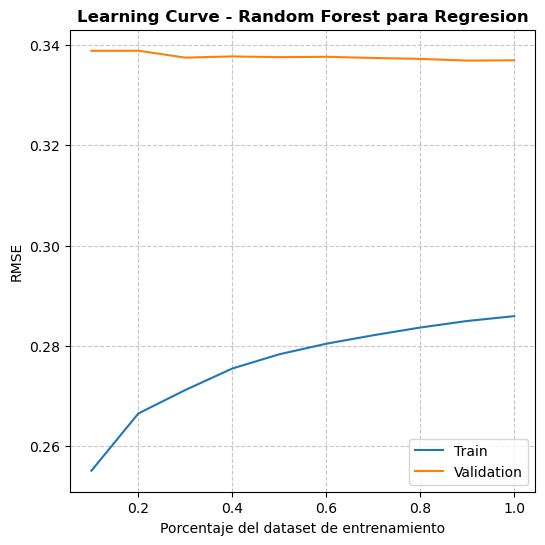

In [24]:
plot_learning_curves_randomforest_regression(X_train_regresion, y_train_regresion, X_val_regresion, y_val_regresion, **mejores_parametros)

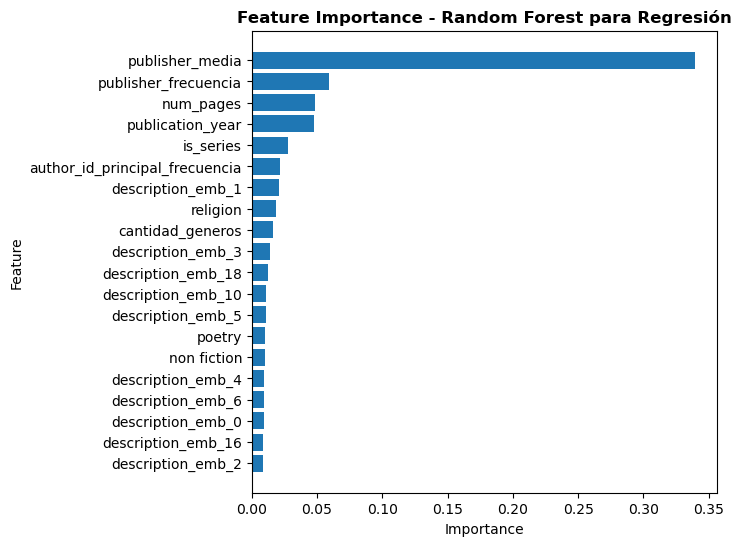

In [25]:
importancias_coef_rf_reg = pd.DataFrame({"feature": columnas_regresion, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresión")

## Random Forest con features avanzadas - Clasificacion

Uso rebalanceo undersampling + cost re weight, con los pesos y cantidades optimos encontrados en Modelo Base.

In [26]:
pesos_undersampling_cost = {1:8, 2:10, 3:2, 4:1, 5:3}
pesos_cost = {1:8, 2:2, 3:2, 4:1, 5:5}

def grid_search_rf_clasificacion(pesos, X, y):
    RandomForestGridSearchClasificacion = RandomForestClassifier(random_state = 42, class_weight = pesos)

    #uso las mismas opciones de hiperparametros q use en regresion, y los mismos indices para obtener los subconjuntos
    grid = GridSearchCV(estimator = RandomForestGridSearchClasificacion, param_grid = parametros_grid_search_rf, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
    grid.fit(X, y)

    mejores_parametros = grid.best_params_
    print(f"Mejores parametros: {mejores_parametros}")
    print(f"Mejor F1 CV: {grid.best_score_}")
    return mejores_parametros

def evaluar_modelo_rf_clasificacion(mejores_parametros, pesos, X_train, y_train, X_val, y_val):
    modeloRandomForestClasificacion = RandomForestClassifier(**mejores_parametros, random_state = 42, class_weight = pesos)
    modeloRandomForestClasificacion.fit(X_train, y_train)

    y_pred_train_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_train))
    y_pred_val_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_val))

    metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloRandomForestClasificacion, y_train)
    metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloRandomForestClasificacion, y_val)
    tabla_metricas_rf_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
    display(tabla_metricas_rf_clasificacion)

    cm_train = confusion_matrix(y_train, y_pred_train_modeloRandomForestClasificacion)
    cm_val = confusion_matrix(y_val, y_pred_val_modeloRandomForestClasificacion)
    plot_confusion_matrix(cm_train, cm_val)
    return tabla_metricas_rf_clasificacion, modeloRandomForestClasificacion

### Cost + undersampling

Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time=  54.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time=  54.7s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time=  54.8s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time=  54.8s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time=  54.7s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time=  54.9s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=300; total time=  54.8s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimato

,Train,Validation
Accuracy,0.815313,0.746654
Precision,0.666054,0.301511
Recall,0.399756,0.278275
F1,0.427285,0.278822


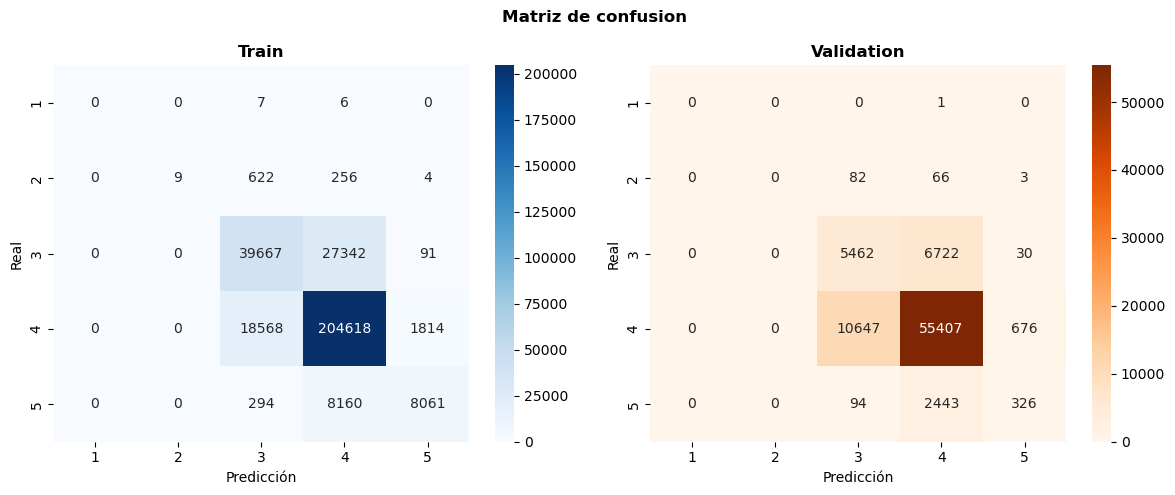

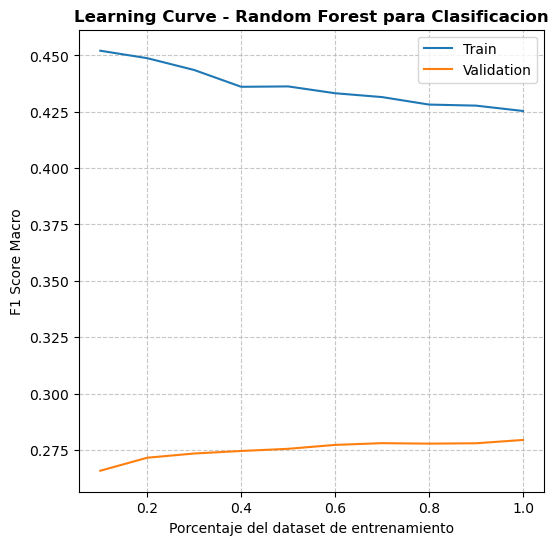

In [27]:
mejores_parametros = grid_search_rf_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling)
tabla_metricas_rf_clasificacion_undersampling_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion, pesos=pesos_undersampling_cost, **mejores_parametros)

Analizamos la feature importance:

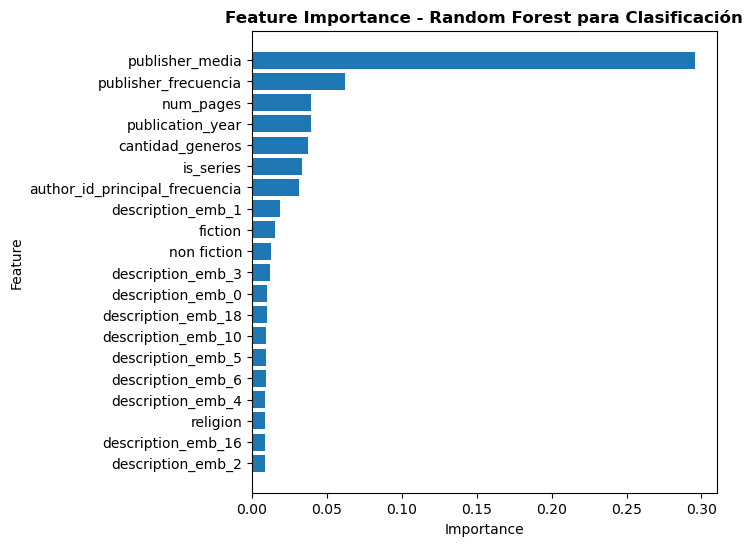

In [28]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificación")

### Cost sin undersampling

Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.4min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimato

,Train,Validation
Accuracy,0.856753,0.808648
Precision,0.477970,0.323720
Recall,0.350908,0.244195
F1,0.382072,0.256554


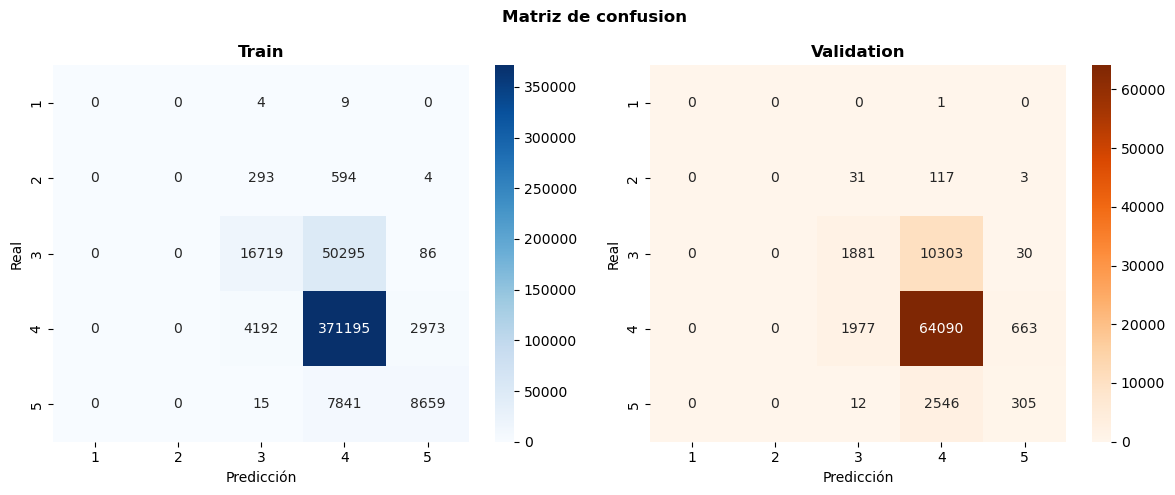

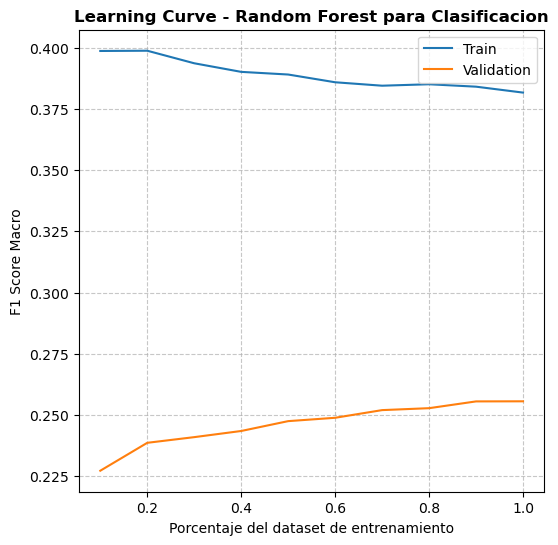

In [29]:
mejores_parametros = grid_search_rf_clasificacion(pesos_cost, X_sub_clasificacion, y_sub_clasificacion)
tabla_metricas_rf_clasificacion_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_cost, X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion, pesos=pesos_cost, **mejores_parametros)

Analizamos la feature importance:

In [ ]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificación")

## XGBoost con features avanzadas - Regresion

Empiezo con grid search para buscar los mejores hiperparametros:

In [ ]:
XGBoostGridSearchRegresion = XGBRegressor(random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2)
grid.fit(X_sub_regresion, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

In [ ]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_regresion, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_regresion)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_regresion)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
tabla_metricas_xgboost_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
display(tabla_metricas_xgboost_regresion)

In [ ]:
plot_learning_curves_xgboost_regression(X_train_regresion, y_train_regresion, X_val_regresion, y_val_regresion, **mejores_parametros)

In [ ]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": columnas_regresion, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresión")

## XGBoost con features avanzadas - Clasificacion

XGBoost solo trabaja con clases empezando desde 0, (aunque nuestras estrellas vayan de 1 a 5). Para poder entrenar con este modelo, transformo temporalmente el target restando 1. Luego, para volver a las clases normales, sumo 1 a la prediccion.

In [ ]:
#transformaciones temporales
y_sub_undersampling_temp = y_sub_clasificacion_undersampling - 1
y_sub_temp = y_sub_clasificacion - 1
y_train_undersampling_temp = y_train_undersampling - 1
y_train_temp = y_train_clasificacion - 1

#exactamente los mismos pesos que antes pero con las clases - 1
pesos_undersampling_cost_xgb = {0:8, 1:10, 2:2, 3:1, 4:3}
pesos_cost_xgb = {0:8, 1:2, 2:2, 3:1, 4:5}

In [ ]:
def grid_search_xgb_clasificacion(pesos, X, y):
    pesos_transformados_sub = np.array([pesos[y_i] for y_i in y])
    XGBoostGridSearchClasificacion = XGBClassifier(objective = "multi:softmax", num_class = 5, random_state = 42) 

    #uso los mismos indices para obtener los subconjuntos
    grid = GridSearchCV(estimator = XGBoostGridSearchClasificacion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
    grid.fit(X, y, sample_weight = pesos_transformados_sub)

    mejores_parametros = grid.best_params_
    print(f"Mejores parametros: {mejores_parametros}")
    print(f"Mejor F1 CV: {grid.best_score_}")
    return mejores_parametros

def evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos, X_train, y_train, X_val, y_val):
    pesos_transformados_train = np.array([pesos[y] for y in y_train])
    modeloXGBoostClasificacion = XGBClassifier(**mejores_parametros, objective = "multi:softmax", num_class = 5, random_state = 42) 
    modeloXGBoostClasificacion.fit(X_train, y_train, sample_weight = pesos_transformados_train) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

    y_pred_train = (modeloXGBoostClasificacion.predict(X_train))
    y_pred_val = (modeloXGBoostClasificacion.predict(X_val))
    #volvemos a las clases originales sumando 1
    y_train = y_train + 1
    y_pred_train_modeloXGBoostClasificacion = y_pred_train + 1
    y_pred_val_modeloXGBoostClasificacion = y_pred_val + 1

    #calculo las metricas usando las clases originales entre 1 y 5
    metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloXGBoostClasificacion, y_train)
    metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloXGBoostClasificacion, y_val)
    tabla_metricas_xgboost_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
    display(tabla_metricas_xgboost_clasificacion)

    cm_train = confusion_matrix(y_train, y_pred_train_modeloXGBoostClasificacion)
    cm_val = confusion_matrix(y_val, y_pred_val_modeloXGBoostClasificacion)
    plot_confusion_matrix(cm_train, cm_val)
    return tabla_metricas_xgboost_clasificacion, modeloXGBoostClasificacion

### Cost + undersampling

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_undersampling_cost_xgb, X_sub_undersampling, y_sub_undersampling_temp)
tabla_metricas_xgb_clasificacion_undersampling_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_undersampling_cost_xgb, X_train_undersampling, y_train_undersampling_temp, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion, pesos=pesos_undersampling_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

In [ ]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificación")

### Cost sin undersampling

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_cost_xgb, X_sub_clasificacion, y_sub_temp)
tabla_metricas_xgb_clasificacion_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_cost_xgb, X_train_clasificacion, y_train_temp, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion, pesos = pesos_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

In [ ]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificación")

## Red neuronal con features avanzadas - Regresion

In [ ]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

Realizamos el Grid Search:

In [ ]:
mejor_r2 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                modelo = MLP_regresion(input_size = X_sub_regresion.shape[1], hidden_layers = capas_ocultas, activation = activacion, dropout = dropout).to(device)
                r2 = run_grid_search_pytorch_regresion(modelo =modelo, learning_rate = lr, model_name = "MLP Regresion", X_train = X_sub_regresion, y_train = y_sub_regresion, X_val = X_val_regresion, y_val = y_val_regresion, device = device, epochs = 30)
                if r2 > mejor_r2:
                    mejor_r2 = r2
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

In [ ]:
modelo_regresion = MLP_regresion(input_size = X_train_regresion.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_regresion(modelo_regresion, "Modelo Regresion", X_train_regresion, y_train_regresion, X_val_regresion, y_val_regresion, device, learning_rate = mejores_parametros["lr"])
tabla_metricas_mlp_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
display(tabla_metricas_mlp_regresion)

Las redes neuronales con pytorch no tienen un atributo para acceder a la feature importance, a diferencia de XGBoost o Random Forest. Para simular esto, se agarra por separado cada feature y se la mezcla (de esta manera se descorrelaciona la salida del modelo con esta feature). Despues, se predice con esa nueva feature y se evalua la diferencia con el X original. A mayor diferencia mayor impacto tiene la feature. 

In [ ]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_regresion, y_val_regresion, columnas_regresion, device, metric_fn = mean_squared_error, higher_is_better = False, n_repeats = 10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n = 20, title = "Feature Importance - Modelo Regresión (PyTorch)")

## Red neuronal con features avanzadas - Clasificacion

La red neuronal tambien necesita que las clases empiecen en 0, por lo que adentro de las funciones manejo los conjuntos de y restando 1, y luego sumando 1 a la prediccion. 

### Cost sin undersampling

In [ ]:
mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout = {dropout}, lr = {lr}, activacion = {activacion.__name__}")
                modelo = MLP_clasificacion(input_size = X_sub_clasificacion.shape[1], hidden_layers = capas_ocultas, n_classes = 5, activation = activacion, dropout = dropout).to(device)
                f1 = run_grid_search_pytorch_clasificacion(modelo = modelo, learning_rate = lr, model_name = "MLP Clasificacion", X_train = X_sub_clasificacion, y_train = y_sub_clasificacion, X_val = X_val_clasificacion, y_val = y_val_clasificacion, device = device, epochs = 30, pesos = pesos_cost)
                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

In [ ]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_clasificacion.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_cost)
tabla_metricas_mlp_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
display(tabla_metricas_mlp_clasificacion)

In [ ]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_clasificacion, y_val_clasificacion, columnas_clasificacion, device, metric_fn = accuracy_score, higher_is_better = True, n_repeats = 10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n = 20, title = "Feature Importance - Modelo Clasificacion (PyTorch)")

### Cost + undersampling

In [ ]:
mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout = {dropout}, lr = {lr}, activacion = {activacion.__name__}")
                modelo = MLP_clasificacion(input_size = X_sub_undersampling.shape[1], hidden_layers = capas_ocultas, n_classes = 5, activation = activacion, dropout = dropout).to(device)
                f1 = run_grid_search_pytorch_clasificacion(modelo = modelo, learning_rate = lr, model_name = "MLP Clasificacion", X_train = X_sub_undersampling, y_train = y_sub_clasificacion_undersampling, X_val = X_val_clasificacion, y_val = y_val_clasificacion, device = device, epochs = 30, pesos = pesos_undersampling_cost)
                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

In [ ]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_undersampling.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
display(tabla_metricas_mlp_clasificacion_undersampling)

In [ ]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_clasificacion, y_val_clasificacion, columnas_clasificacion, device, metric_fn = accuracy_score, higher_is_better = True, n_repeats = 10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")

## Comparando modelos

In [ ]:
print("Comparacion de tablas de metricas:")

print("\nRANDOM FOREST:")
print("Regresion:")
display(tabla_metricas_rf_regresion)
print("\nClasificacion undersampling + cost:")
display(tabla_metricas_rf_clasificacion_undersampling_cost)
print("\nClasificacion cost:")
display(tabla_metricas_rf_clasificacion_cost)

print("\nXGBOOST:")
print("Regresion:")
display(tabla_metricas_xgboost_regresion)
print("\nClasificacion undersampling + cost:")
display(tabla_metricas_xgb_clasificacion_undersampling_cost)
print("\nClasificacion cost:")
display(tabla_metricas_xgb_clasificacion_cost)

print("\nRED NEURONAL:")
print("Regresion:")
display(tabla_metricas_mlp_regresion)
print("\nClasificacion undersampling + cost:")
display(tabla_metricas_mlp_clasificacion)
print("\nClasificacion cost:")
display(tabla_metricas_mlp_clasificacion_undersampling)